# Dashboard Top 100 Steam

**Steam Dashboard** to projekt służący do analizy danych na temat 100 najpopularniejszych gier na platformie Steam, opartych na danych z ostatnich dwóch tygodni. Projekt zawiera analizę wstępną, czyszczenie danych oraz interaktywną prezentację wyników przy użyciu aplikacji Streamlit.

## Wymagania

- **Python 3.10**
- Biblioteki:
  - `requests`
  - `pandas`
  - `streamlit`
  - `numpy`
  - `matplotlib`
  - `seaborn`
  - Inne pakiety według potrzeb

## Uruchamianie projektu

Projekt składa się z następujących plików:
- **s34596_final.ipynb** – zawiera kod do pobierania, łączenia i czyszczenia danych.
- **dashboard.py** – główna aplikacja Streamlit prezentująca wyniki analizy oraz interaktywne wykresy.
- **top100.csv** – plik z danymi wejściowymi.



In [ ]:
# wpisując poniższe polecenie stworzymy nowe środowisko conda wraz z wymaganymi bibliotekami i Pythonem 3.10 dla stabilności paczek
conda create -n s34596 python=3.10 requests pandas streamlit numpy matplotlib seaborn -y


Aby uruchomić aplikację Streamlit, użyj poniższego polecenia w terminalu:
```bash
streamlit run dashboard.py
```
- Wykrycie trendów i zależności pomiędzy liczbą graczy, liczbą właścicieli oraz innymi zmiennymi.
- Ocena wpływu gatunków gier na ich popularność oraz analiza udziału poszczególnych gatunków w zbiorze.
- Prezentacja wyników przy użyciu interaktywnych wykresów, co umożliwia dynamiczną eksplorację danych.

## Etapy analizy

### 1. Czyszczenie danych

- **Usunięcie duplikatów:**  
  Sprawdzenie zbioru danych pod kątem duplikatów i usunięcie powtarzających się rekordów.

- **Obsługa brakujących wartości:**  
  Uzupełnienie lub usunięcie wierszy z brakującymi danymi, aby zapewnić poprawność dalszych analiz.

- **Konwersja typów danych:**  
  Przekształcenie kolumny `release_date` na format daty oraz wyodrębnienie roku wydania, co zapisano w kolumnie `release_year`.

- **Ekstrakcja gatunków:**  
  Z pola `description` wyciągnięto listę gatunków i zapisano ją w nowej kolumnie `genres` (np. `["Action", "Strategy", "Free To Play"]`).

### 2. Eksploracja danych (EDA)

- **Statystyki opisowe:**  
  Obliczenie podstawowych statystyk opisowych, takich jak średnia, mediana czy odchylenie standardowe dla kluczowych zmiennych (np. `price`).

- **Wizualizacje rozkładu:**  
  Stworzenie histogramów oraz wykresów pudełkowych, aby zobaczyć rozkład liczby graczy oraz innych zmiennych.


- **Analiza gatunków:**  
  - **Udział gatunków:** Obliczenie procentowego udziału poszczególnych gatunków w zbiorze gier, gdzie jeśli gra posiada dany gatunek, jest wliczana do sumy dla tego gatunku.
  - **Wizualizacja:** Wykres słupkowy prezentujący procentowy udział poszczególnych gatunków.

- **Analiza trendów czasowych:**  
  Na podstawie kolumny `release_year` stworzono wykres słupkowy pokazujący liczbę gier wydanych w poszczególnych latach, co pozwala na identyfikację trendów wydawniczych w czasie.

### 3. Prezentacja wyników

- **Interaktywna aplikacja Streamlit:**  
  Wyniki analizy są prezentowane w formie interaktywnego dashboardu, który umożliwia filtrowanie danych (np. po wydawcy, gatunku) oraz dynamiczną wizualizację wyników.

- **Wykresy interaktywne:**  
  W dashboardzie znajdują się m.in.:
  - Wykres pudełkowy (lub violin plot) porównujący rozkład liczby graczy dla gier darmowych i płatnych.
  - Wykres korelacji (heatmap) analizujący zależności pomiędzy kluczowymi zmiennymi.
  - Wykres słupkowy przedstawiający udział gatunków oraz liczby gier wg roku wydania.

## Wnioski

Na podstawie przeprowadzonej analizy można wyciągnąć następujące wnioski:
- **Trendy popularności:** Jak zmieniała się popularność gier na Steam w zależności od roku wydania.
- **Rola gatunków:** Które gatunki dominują wśród najpopularniejszych gier oraz jaki mają udział procentowy.
- **Zależności między zmiennymi:** Jak liczba właścicieli wpływa na liczbę aktywnych graczy oraz inne istotne relacje w danych.

Dalsza analiza może obejmować pogłębione badanie korelacji między zmiennymi oraz zastosowanie modeli uczenia maszynowego do przewidywania popularności gier.

In [11]:
#import bibliotek
import requests
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [2]:
# Dwustopniowe podejście ściągające listę gier ze Steamspy i uzupełniające o szczegółowe dane używając Steam API

# Pobierz top 100 gier używając publicznego API SteamSpy
steamspy_url = "https://steamspy.com/api.php?request=top100in2weeks"
response = requests.get(steamspy_url)

if response.status_code == 200:
    steamspy_data = response.json()
    # klucz: appid
    top_game_ids = list(steamspy_data.keys())
    print("Successfully fetched top 100 games from SteamSpy.")
else:
    print("Error fetching data from SteamSpy:", response.status_code)
    top_game_ids = []

# Dla każdej gry pobierz szczegółowe dane
steam_api_base_url = "https://store.steampowered.com/api/appdetails"
steam_api_details = {}

for appid in top_game_ids:
    params = {"appids": appid}
    api_response = requests.get(steam_api_base_url, params=params)
    
    if api_response.status_code == 200:
        # stwórz klucz: appid w formacie JSON
        game_data = api_response.json().get(str(appid), {})
        steam_api_details[appid] = game_data
    else:
        print(f"Error fetching details for appid {appid}: {api_response.status_code}")

combined_data = []

for appid, spy_info in steamspy_data.items():
    details = steam_api_details.get(appid, {})

    # jeżeli API zwróci zagnieżdżoną strukturę z kluczem "data", wyciągnij dodatkowe informacje

    if isinstance(details, dict) and details.get("success", False) and "data" in details:
        details = details["data"]
    else: 
        details = {}

    merged_info = {"appid": appid, **spy_info, **details}
    combined_data.append(merged_info)

df = pd.DataFrame(combined_data)

display(df.head())

# `steamspy_data` zawiera zagregowane dane odnośnie czasu gry i rankingu dla top 100 gier
# `steam_api_details` przechowuje szczegółowe dane ściągnięte ze Steam API dla każdej gry

Successfully fetched top 100 games from SteamSpy.


,appid,name,developer,publisher,score_rank,positive,negative,userscore,owners,average_forever,...,background_raw,content_descriptors,ratings,achievements,legal_notice,controller_support,price_overview,ext_user_account_notice,drm_notice,demos
0,570,Dota 2,Valve,Valve,,1981635,447886,0,"200,000,000 .. 500,000,000",43053,...,https://shared.akamai.steamstatic.com/store_it...,"{'ids': [5], 'notes': 'Dota 2 includes fantasy...","{'kgrb': {'rating': '12', 'descriptors': '12 (...",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,730,Counter-Strike 2,Valve,Valve,,7437295,1125792,0,"100,000,000 .. 200,000,000",31363,...,https://shared.akamai.steamstatic.com/store_it...,"{'ids': [2, 5], 'notes': 'Includes intense vio...","{'usk': {'rating': '16', 'descriptors': 'Gewal...","{'total': 1, 'highlighted': [{'name': 'A New B...",NaN,NaN,NaN,NaN,NaN,NaN
2,578080,PUBG: BATTLEGROUNDS,PUBG Corporation,"KRAFTON, Inc.",,1479885,1021487,0,"50,000,000 .. 100,000,000",21996,...,https://shared.akamai.steamstatic.com/store_it...,"{'ids': [2, 5], 'notes': None}","{'kgrb': {'rating': '18', 'descriptors': '폭력성'...","{'total': 37, 'highlighted': [{'name': 'Last S...","© 2017 KRAFTON, Inc.<br />\r\nPUBG: BATTLEGROU...",NaN,NaN,NaN,NaN,NaN
3,1623730,Palworld,Pocketpair,Pocketpair,,347261,21611,0,"50,000,000 .. 100,000,000",3466,...,https://shared.akamai.steamstatic.com/store_it...,"{'ids': [], 'notes': None}","{'dejus': {'rating': 'l'}, 'steam_germany': {'...","{'total': 33, 'highlighted': [{'name': 'Hillsi...",NaN,full,"{'currency': 'CAD', 'initial': 3899, 'final': ...",NaN,NaN,NaN
4,1172470,Apex Legends™,Respawn,Electronic Arts,,658390,320800,0,"50,000,000 .. 100,000,000",9024,...,https://shared.akamai.steamstatic.com/store_it...,"{'ids': [], 'notes': None}","{'esrb': {'rating': 't', 'descriptors': 'Blood...","{'total': 12, 'highlighted': [{'name': 'The Pl...","Germany, Austria, and Switzerland only: EA’S P...",full,NaN,EA Account (Supports Linking to Steam Account),NaN,NaN


In [6]:
def extract_date(val):
    # jeżeli jest już słownikiem, wyciągnij po kluczu "date"
    if isinstance(val, dict):
        return val.get("date", np.nan)
    # Spróbuj przekonwertować do słownika
    if isinstance(val, str):
        try:
            parsed_val = ast.literal_eval(val)
            if isinstance(parsed_val, dict):
                return parsed_val.get("date", np.nan)
        except Exception as e:
            return np.nan
    return np.nan

def extract_genres(description):
    # jeśli 'description' jest ciągiem znaków, spróbuj przekonwertować go na listę
    if isinstance(description, str):
        try:
            data = ast.literal_eval(description)  # próba konwersji przy użyciu ast.literal_eval
        except Exception as e:
            try:
                data = json.loads(description)  # jeśli ast.literal_eval nie zadziała, spróbuj json.loads
            except Exception as e2:
                return []  # w przypadku błędu zwróć pustą listę
    elif isinstance(description, list):
        data = description  # jeśli 'description' już jest listą, przypisz ją bez zmian
    else:
        return []  #W pozostałych przypadkach zwróć pustą listę

    # Sprawdź, czy data jest listą i wyciągnij wartość klucza 'description' z każdego słownika
    if isinstance(data, list):
        return [item.get("description") for item in data if isinstance(item, dict) and "description" in item]
    return []

necessary_columns = [
    "appid",             # unikalne id gry
    "name",              # tytuł
    "ccu"                # concurrent users z wczoraj
    "average_2weeks",    # Średni lczas gry
    "price",             # cena podana w centach USD
    "release_date",      # data wydania
    "median_2weeks",     # Mediana czasu gry
    "owners",            # orientacyjna liczba posiadaczy gry
    "developer",         # deweloper
    "publisher",         # wydawca
    "genres",            # kategorie/gatunki gry
    "is_free"           # bool płatna/darmowa gra
]

# wybieramy jedynie potrzebne do analizy kolumny
existing_columns = [col for col in necessary_columns if col in df.columns]
df_cleaned = df[existing_columns].copy()

# display(df.head())

# Dalsze oczyszczanie:
# 
# usuń duplikaty (niepotrzebne)
# df_cleaned.drop_duplicates(inplace=True)

# przekonwertuj dane w kolumnie "release_date" do formatu daty
if "release_date" in df_cleaned.columns:
    df_cleaned["release_date"] = df_cleaned["release_date"].apply(extract_date)
    df_cleaned["release_date"] = pd.to_datetime(df_cleaned["release_date"], format="%d %b, %Y", errors="coerce").dt.date

# przekonwertuj dane ze słownika o dwóch kluczach: 'id' i 'description' dla kolumny "genres" na listę nazw gatunków
df_cleaned['genres'] = df_cleaned['genres'].apply(extract_genres)
display(df_cleaned.head())


,appid,name,price,release_date,median_2weeks,owners,developer,publisher,genres,is_free
0,570,Dota 2,0,2013-07-09,788,"200,000,000 .. 500,000,000",Valve,Valve,"[Action, Strategy, Free To Play]",True
1,730,Counter-Strike 2,0,2012-08-21,346,"100,000,000 .. 200,000,000",Valve,Valve,"[Action, Free To Play]",True
2,578080,PUBG: BATTLEGROUNDS,0,2017-12-21,347,"50,000,000 .. 100,000,000",PUBG Corporation,"KRAFTON, Inc.","[Action, Adventure, Massively Multiplayer, Fre...",True
3,1623730,Palworld,2999,2024-01-18,409,"50,000,000 .. 100,000,000",Pocketpair,Pocketpair,"[Action, Adventure, Indie, RPG, Early Access]",False
4,1172470,Apex Legends™,0,2020-11-04,299,"50,000,000 .. 100,000,000",Respawn,Electronic Arts,"[Action, Adventure, Free To Play]",True


Unikalnych wartości dla 'name': 100


name
Dota 2                                       1
Ring of Elysium                              1
The Sims™ 4                                  1
Sekiro™: Shadows Die Twice - GOTY Edition    1
7 Days to Die                                1
Name: count, dtype: int64

Unikalnych wartości dla 'developer': 81


developer
Valve                      12
FromSoftware, Inc.          2
Wargaming Group Limited     2
Endnight Games Ltd          2
CD PROJEKT RED              2
Name: count, dtype: int64

Unikalnych wartości dla 'publisher': 74


publisher
Valve                      13
Electronic Arts             5
Rockstar Games              3
Ubisoft                     2
Wargaming Group Limited     2
Name: count, dtype: int64

Unikalnych wartości dla 'price': 23


price
0       32
1999    12
5999    10
999      8
2999     7
Name: count, dtype: int64

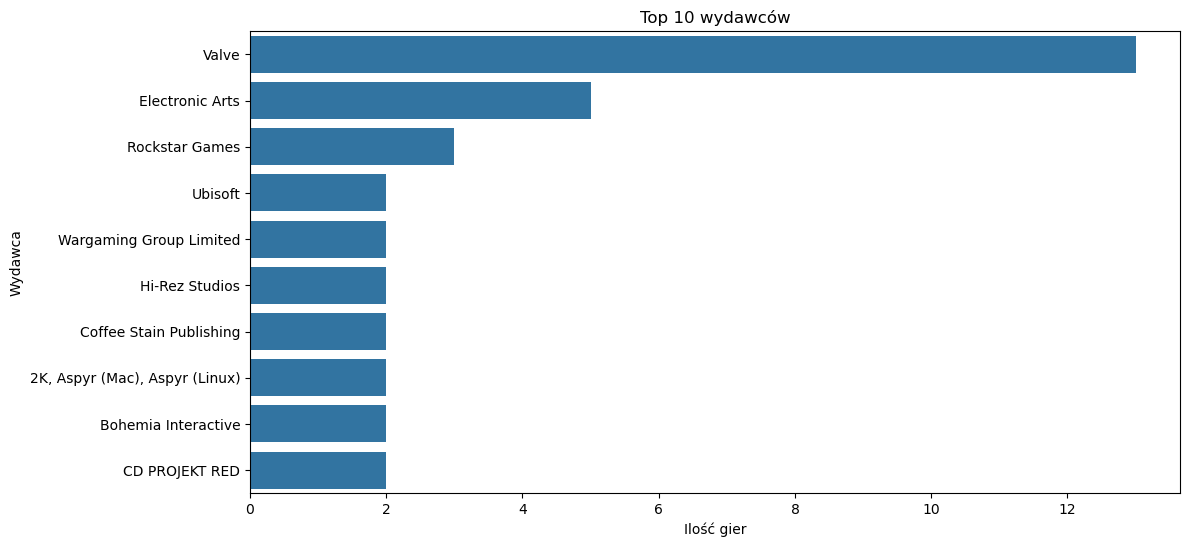

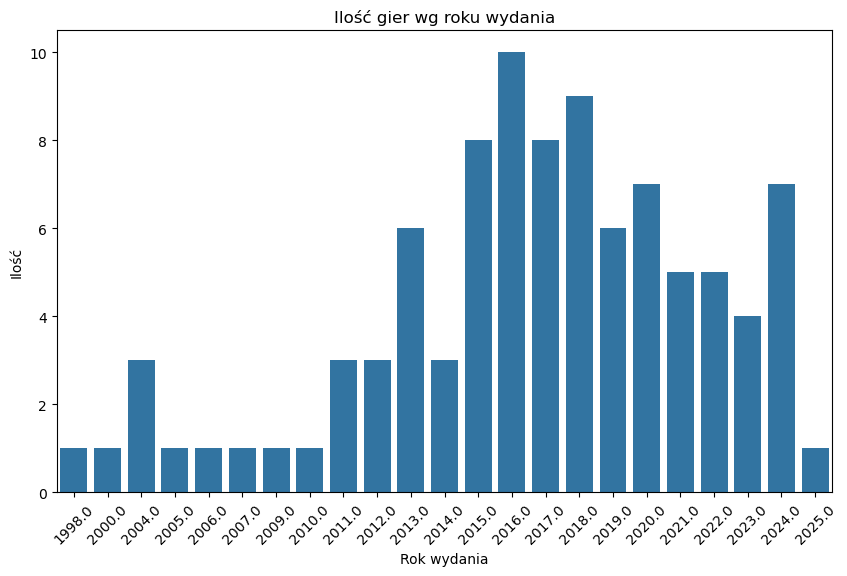

In [7]:
# %matplotlib inline

# # ----------------------------
# # Descriptive Statistics
# # ----------------------------
# print("Descriptive statistics for numeric columns:")
# display(df_cleaned.describe())

# Wyświetl unikalne pozycje dla danych kategorycznych z wylistowanych kolumn
categorical_columns = ["name", "developer", "publisher", "price"]
for col in categorical_columns:
    if col in df_cleaned.columns:
        print(f"Unikalnych wartości dla '{col}': {df_cleaned[col].nunique()}")
        display(df_cleaned[col].value_counts().head())

# ----------------------------
# Ewaluacja danych
# ----------------------------

if "publisher" in df_cleaned.columns:
    top_publishers = df_cleaned["publisher"].value_counts().nlargest(10).index
    plt.figure(figsize=(12, 6))
    sns.countplot(data=df_cleaned[df_cleaned["publisher"].isin(top_publishers)], 
                  y="publisher", order=top_publishers)
    plt.title("Top 10 wydawców")
    plt.xlabel("Ilość gier")
    plt.ylabel("Wydawca")
    plt.show()

# 5. Ilość gier wg roku (jeżeli posiada release_date )
if "release_date" in df_cleaned.columns:
    # Convert release_date to datetime if not already (handles date objects as well)
    df_cleaned["release_date"] = pd.to_datetime(df_cleaned["release_date"], errors="coerce")
    df_cleaned["release_year"] = df_cleaned["release_date"].dt.year
    plt.figure(figsize=(10, 6))
    order_years = sorted(df_cleaned["release_year"].dropna().unique())
    sns.countplot(data=df_cleaned, x="release_year", order=order_years)
    plt.title("Ilość gier wg roku wydania")
    plt.xlabel("Rok wydania")
    plt.ylabel("Ilość")
    plt.xticks(rotation=45)
    plt.show()

In [8]:
#  eksport df do csv dla łatwiejszej obróbki; dane są odświeżane raz dziennie, więc nie ma potrzeby callbacków()

csv_file = "top100.csv"
df.to_csv(csv_file, index=False)

print(f"Dostarczono dane do {csv_file}")

Dostarczono dane do top100.csv
